# End-to-end 4-bit training, reproduced in emulation - runs on a MacBook
### NVFP4 forward, MXFP8 backward, 4-over-6 scaling, stochastic rounding, RHT + S2F6 - every number format built from scratch and tested

**Source.** Thinking Machines Lab, *End-to-End 4-Bit Training* (blog post, https://thinkingmachines.ai/blog/end-to-end-4-bit-training/). The post trains a large MoE model with a native 4-bit forward pass on NVIDIA GB300 racks. Definitions the post defers to other papers are taken from those papers, whose text I read directly:
- NVIDIA, *Pretraining LLMs with NVFP4*, [arXiv 2509.25149](https://arxiv.org/abs/2509.25149) - the format, two-level scaling, 2D weight scaling, RHT, stochastic rounding.
- Cook et al., *Four Over Six*, [arXiv 2512.02010](https://arxiv.org/abs/2512.02010) - adaptive block scaling (4/6).

**What this notebook is, and is not.** A MacBook has no FP4 tensor cores. Everything here is **emulation**: values are rounded to the exact grid of each format and then multiplied in float32. That reproduces the *numerics* (error, bias, training behaviour) but gives **no speed-up**. The speed-ups, the kernels and the NVLink communication in the post need Blackwell hardware; the companion notebook `02_nvfp4_native_on_blackwell_cuda.ipynb` covers the native path.

| step | question | how it is checked |
|---|---|---|
| 1 | what are NVFP4 and MXFP8, and what do they cost in bits? | arithmetic + figure |
| 2 | how does two-level block scaling work? | hand-worked example reproduced exactly |
| 3 | what is 4/6 and does it lower the error? | the paper's Table 2 + measured error |
| 4 | why stochastic rounding? | the post's worked example + measured bias |
| 5 | what is the transpose problem, and the post's fix? | measured on a weight matrix |
| 6 | the recipe as one layer (forward NVFP4, backward MXFP8) | gradient error and unbiasedness |
| 7 | does a small transformer train with it? | 5 configurations, 2 seeds |
| 8 | RHT + S2F6 for communication | measured error |
| 9 | does it all run on this Mac (cpu and Apple GPU)? | parity tests + the repo's unit tests |

Claims from the post that this notebook **cannot** test are listed in Step 10.

In [1]:
import math, sys, time, subprocess
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

sys.path.insert(0, str(Path.cwd()))
import fp4kit as k

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
NV_C, MX_C, HP_C, INT_C, BAD_C = "#2f9e44", "#e8590c", "#495057", "#1c7ed6", "#c92a2a"     # green NVFP4, orange MXFP8, grey high precision

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")

def rel_mse(q, x): return (((q - x) ** 2).mean() / (x ** 2).mean()).item()
print("torch", torch.__version__, "| Apple GPU (mps) available:", torch.backends.mps.is_available())

torch 2.14.1 | Apple GPU (mps) available: True


## Step 1 - The formats and what they cost

A **block-scaled** format stores small elements plus one shared scale per block of values. Cost per value = element bits + scale bits / block size.

| format | elements | block | scale | bits / value |
|---|---|---|---|---|
| **NVFP4** | FP4 (E2M1) | 16 | E4M3 per block, **+ one FP32 per tensor** | 4 + 8/16 = **4.5** |
| MXFP4 | FP4 (E2M1) | 32 | E8M0 (power of two) | 4 + 8/32 = 4.25 |
| **MXFP8** | FP8 (E4M3) | 32 | E8M0 | 8 + 8/32 = **8.25** |
| BF16 | - | - | - | 16 |

The FP32 outer scale is one number per tensor (negligible). The post's table lists NVFP4 at 4.5, MXFP8 at 8.25 and BF16 at 16 bits and says NVFP4 uses 3.6× fewer bits than BF16.

NVFP4   4.50 bits/value
MXFP4   4.25 bits/value
MXFP8   8.25 bits/value
BF16   16.00 bits/value
PASS - bits/value: NVFP4 4.5, MXFP8 8.25 (as in the post) 
PASS - NVFP4 uses 3.6x fewer bits than BF16 | 3.56x
PASS - FP4 magnitudes are 0, .5, 1, 1.5, 2, 3, 4, 6 


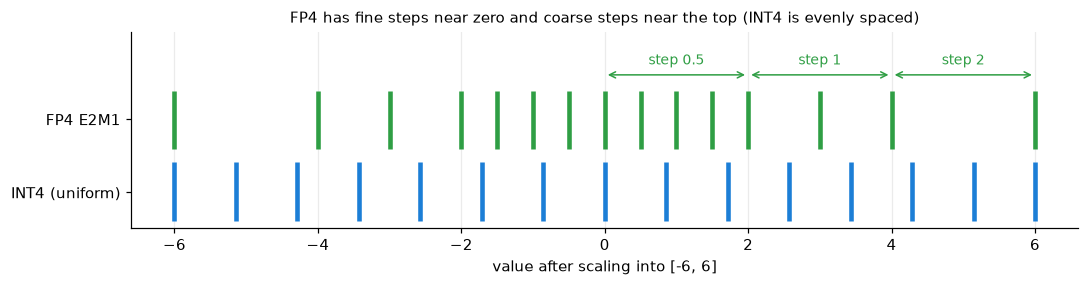

In [2]:
fmts = {"NVFP4": k.bits_per_value(4, 8, 16), "MXFP4": k.bits_per_value(4, 8, 32), "MXFP8": k.bits_per_value(8, 8, 32), "BF16": 16.0}
for n, b in fmts.items(): print(f"{n:6s} {b:5.2f} bits/value")
check("bits/value: NVFP4 4.5, MXFP8 8.25 (as in the post)", fmts["NVFP4"] == 4.5 and fmts["MXFP8"] == 8.25)
check("NVFP4 uses 3.6x fewer bits than BF16", round(16 / fmts["NVFP4"], 1) == 3.6, f"{16 / fmts['NVFP4']:.2f}x")
check("FP4 magnitudes are 0, .5, 1, 1.5, 2, 3, 4, 6", k.FP4_GRID.tolist() == [0, .5, 1, 1.5, 2, 3, 4, 6])

# figure: the 15 FP4 values versus 15 INT4 values spread over the same range
fp4 = torch.cat([-k.FP4_GRID.flip(0)[:-1], k.FP4_GRID]); int4 = torch.arange(-7, 8) * 6 / 7
fig, ax = plt.subplots(figsize=(10, 2.7))
ax.vlines(fp4, 0.55, 1.0, color=NV_C, lw=3); ax.vlines(int4, 0.0, 0.45, color=INT_C, lw=3)
for a, b, step in [(0, 2, "step 0.5"), (2, 4, "step 1"), (4, 6, "step 2")]:
    ax.annotate("", xy=(b, 1.12), xytext=(a, 1.12), arrowprops=dict(arrowstyle="<->", color=NV_C)); ax.text((a + b) / 2, 1.2, step, ha="center", color=NV_C, fontsize=9)
ax.set_yticks([0.22, 0.78]); ax.set_yticklabels(["INT4 (uniform)", "FP4 E2M1"]); ax.set_ylim(-0.05, 1.45); ax.set_xlim(-6.6, 6.6); ax.grid(axis="y", alpha=0)
ax.set_xlabel("value after scaling into [-6, 6]"); ax.set_title("FP4 has fine steps near zero and coarse steps near the top (INT4 is evenly spaced)", fontsize=10)
plt.tight_layout(); plt.show()

**The coarse top end matters.** Between 4 and 6 the only FP4 values are 4 and 6, so a scaled value near 5 can be off by up to 1 (i.e. ±20 %). The Four-Over-Six paper identifies exactly these near-maximal values as the main source of NVFP4 error (Step 3).

## Step 2 - Two-level scaling, by hand

Per the NVIDIA paper (Appendix B), for a tensor `x`:

1. **Tensor scale** (FP32): `α = amax(x) / (6 · 448)` - 6 is the largest FP4 value, 448 the largest E4M3 value.
2. **Block scale** (E4M3, one per 16 values): `Δ = e4m3( amax_block / (α · 6) )`.
3. **Elements**: `q = fp4( x / (α · Δ) )`, and the stored tensor decodes as `x ≈ q · Δ · α`.

The block maximum is mapped to 6 (the FP4 maximum). Because Δ is rounded to E4M3 (3 mantissa bits), the maximum lands *near* 6, not exactly on it. Reproducing it with the kit for one block:

In [3]:
torch.manual_seed(1)
x = torch.randn(1, 32) * 3
qt = k.quantize_nvfp4(x)                       # 2 blocks of 16, one outer scale
alpha, delta = qt.alpha.item(), qt.delta.flatten()
print("amax(x)             :", f"{x.abs().max().item():.4f}")
print("outer scale alpha   :", f"{alpha:.6f}   (= amax / 2688)")
for b in range(2):
    xb = x[0, b * 16:(b + 1) * 16]
    d_raw = xb.abs().max().item() / (alpha * 6)
    print(f"block {b}: amax {xb.abs().max():.3f} -> raw delta {d_raw:.3f} -> E4M3 delta {delta[b]:.3f} | q = {qt.q[0, b].tolist()}")
print("max |x - dequant(x)| / amax :", f"{((qt.dequantize() - x).abs().max() / x.abs().max()).item():.4f}")
check("outer scale = amax / (6*448)", math.isclose(alpha, x.abs().max().item() / 2688, rel_tol=1e-6))
check("every q is on the FP4 grid", bool(torch.isin(qt.q.abs(), k.FP4_GRID).all()))
check("block scale is an exact E4M3 number", bool((k.round_e4m3(qt.delta) == qt.delta).all()))

amax(x)             : 6.7367
outer scale alpha   : 0.002506   (= amax / 2688)
block 0: amax 5.061 -> raw delta 336.588 -> E4M3 delta 352.000 | q = [-6.0, -3.0, -2.0, -6.0, -0.5, -2.0, -3.0, -6.0, -2.0, 1.0, -3.0, -1.0, -1.0, 6.0, 1.0, 1.5]
block 1: amax 6.737 -> raw delta 448.000 -> E4M3 delta 448.000 | q = [-2.0, -3.0, 2.0, 0.5, 2.0, 0.5, -2.0, 2.0, 3.0, -0.5, -6.0, -4.0, 0.0, -1.5, -2.0, -0.5]
max |x - dequant(x)| / amax : 0.1063
PASS - outer scale = amax / (6*448) 
PASS - every q is on the FP4 grid 
PASS - block scale is an exact E4M3 number 


## Step 3 - Four Over Six (4/6): pick the better of two scales per block

Standard NVFP4 always maps the block maximum to **6**. 4/6 also tries mapping it to **4**. With a maximum of 4 the grid's useful top step is `3 → 4` (75 % of the maximum) instead of `4 → 6` (66.7 %), which represents near-maximal values better - at the cost of the range above 4. Per block, **quantize twice and keep the version with the lower mean squared error** (the paper tested max-error, MAE and MSE; MSE won). The paper's hand-worked example (Table 2, block size 4, outer scale 1):

X = [10.0, 20.0, 30.0, 40.0]
   scale-6: delta=6.5  q=[1.5, 3.0, 4.0, 6.0]  dequant=[9.75, 19.5, 26.0, 39.0]  mse=4.33
   4/6    : picked 4  delta=10.0  dequant=[10.0, 20.0, 30.0, 40.0]
X = [15.0, 30.0, 120.0, 180.0]
   scale-6: delta=30.0  q=[0.5, 1.0, 4.0, 6.0]  dequant=[15.0, 30.0, 120.0, 180.0]  mse=0.00
   4/6    : picked 6  delta=30.0  dequant=[15.0, 30.0, 120.0, 180.0]
PASS - Table 2 block 1: scale 6 gives [9.75, 19.5, 26, 39] (error 4.33); 4/6 picks scale 4 and is exact 
PASS - Table 2 block 2: scale 6 is already exact, 4/6 keeps it (scale 4 would give error 96.25) 


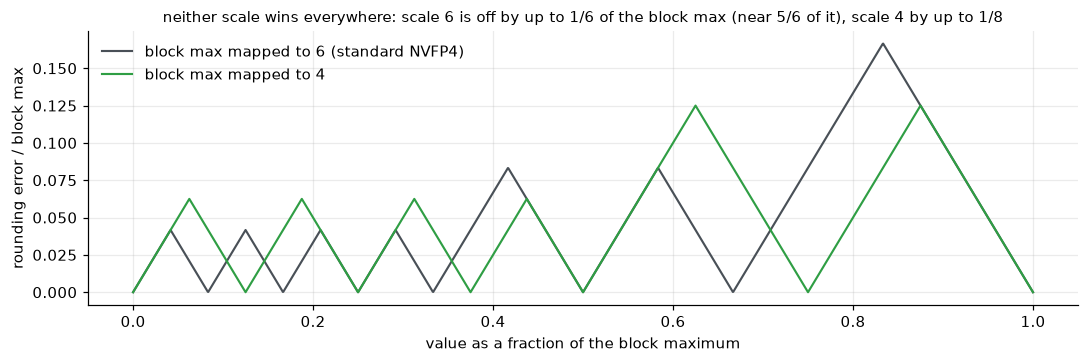

worst-case rounding error / block max:  scale 6 = 0.1665   scale 4 = 0.1250


In [4]:
X = torch.tensor([[10.0, 20, 30, 40], [15.0, 30, 120, 180]])
plain = k.quantize_nvfp4(X, block=4, outer="row", alpha_override=1.0)
ada = k.quantize_nvfp4(X, block=4, outer="row", four_over_six=True, alpha_override=1.0)
for i in range(2):
    print(f"X = {X[i].tolist()}")
    print(f"   scale-6: delta={plain.delta.flatten()[i]:.1f}  q={plain.q[i, 0].tolist()}  dequant={plain.dequantize()[i].tolist()}  mse={((plain.dequantize()[i] - X[i]) ** 2).mean():.2f}")
    print(f"   4/6    : picked {'4' if ada.used4.flatten()[i] else '6'}  delta={ada.delta.flatten()[i]:.1f}  dequant={ada.dequantize()[i].tolist()}")
check("Table 2 block 1: scale 6 gives [9.75, 19.5, 26, 39] (error 4.33); 4/6 picks scale 4 and is exact",
      plain.dequantize()[0].tolist() == [9.75, 19.5, 26.0, 39.0] and bool(ada.used4.flatten()[0]) and ada.dequantize()[0].tolist() == [10, 20, 30, 40])
check("Table 2 block 2: scale 6 is already exact, 4/6 keeps it (scale 4 would give error 96.25)",
      (not bool(ada.used4.flatten()[1])) and ada.dequantize()[1].tolist() == [15, 30, 120, 180])

# why: rounding error as a function of where a value sits inside its block (in units of the block max)
v = torch.linspace(0, 1, 2001)
err = {M: ((k.round_fp4(v * M) - v * M).abs() / M) for M in (6.0, 4.0)}
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(v, err[6.0], color=HP_C, lw=1.4, label="block max mapped to 6 (standard NVFP4)")
ax.plot(v, err[4.0], color=NV_C, lw=1.4, label="block max mapped to 4")
ax.set_xlabel("value as a fraction of the block maximum"); ax.set_ylabel("rounding error / block max")
ax.set_title("neither scale wins everywhere: scale 6 is off by up to 1/6 of the block max (near 5/6 of it), scale 4 by up to 1/8", fontsize=9.5)
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("worst-case rounding error / block max:  scale 6 =", f"{err[6.0].max():.4f}", "  scale 4 =", f"{err[4.0].max():.4f}")

The two curves cross: neither scale is better everywhere, which is why the choice is made **per block from the measured error**, not globally (the paper also shows scaling *every* block to 4 is worse than standard NVFP4).

Now the measurement that matters: relative quantization error (error energy / signal energy) on three kinds of data, for the formats in play. INT4 with a float scale per 16 values is included as a reference.

                                        MXFP4 (E8M0, 32)                 NVFP4           NVFP4 + 4/6 INT4, float scale /16     MXFP8 (reference)
Gaussian                                        1.33e-02              9.08e-03              7.60e-03              7.25e-03              7.05e-04
heavy-tailed (Student-t, 3 dof)                 2.25e-02              8.31e-03              7.65e-03              1.28e-02              6.93e-04
Gaussian + 0.2% large outliers                  2.18e-02              7.26e-03              6.61e-03              8.38e-03              7.47e-04


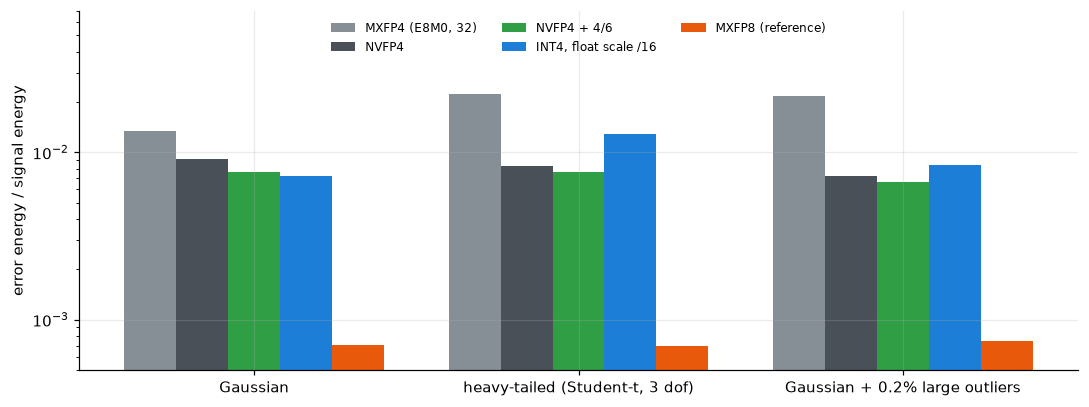

PASS - NVFP4 beats MXFP4 on every data set 
PASS - 4/6 lowers NVFP4 error on every data set | 1.19x / 1.09x / 1.10x
PASS - MXFP8 is ~10x more accurate than any 4-bit format 

Note: on Gaussian data INT4 with a float scale (7.25e-03) is as good as NVFP4 + 4/6 (7.60e-03); FP4's advantage is range inside a block, not a lower error on well-behaved data.


In [5]:
torch.manual_seed(0)
data = {"Gaussian": torch.randn(1024, 512),
        "heavy-tailed (Student-t, 3 dof)": torch.distributions.StudentT(3.0).sample((1024, 512)),
        "Gaussian + 0.2% large outliers": torch.randn(1024, 512) * (1 + 30 * (torch.rand(1024, 512) < 0.002))}
methods = {"MXFP4 (E8M0, 32)": lambda x: k.quantize_mx(x, "mxfp4"),
           "NVFP4": lambda x: k.quantize_nvfp4(x).dequantize(),
           "NVFP4 + 4/6": lambda x: k.quantize_nvfp4(x, four_over_six=True).dequantize(),
           "INT4, float scale /16": lambda x: k.quantize_int4_block(x),
           "MXFP8 (reference)": lambda x: k.quantize_mx(x, "mxfp8")}
R = {d: {m: rel_mse(f(x), x) for m, f in methods.items()} for d, x in data.items()}
print(f"{'':34s}" + "".join(f"{m:>22s}" for m in methods))
for d in R: print(f"{d:34s}" + "".join(f"{R[d][m]:22.2e}" for m in methods))

fig, ax = plt.subplots(figsize=(10, 3.8)); w = 0.16
cols = ["#868e96", HP_C, NV_C, INT_C, MX_C]
for i, m in enumerate(methods): ax.bar(np.arange(3) + (i - 2) * w, [R[d][m] for d in R], w, color=cols[i], label=m)
ax.set_yscale("log"); ax.set_ylim(5e-4, 7e-2); ax.set_xticks(range(3)); ax.set_xticklabels(list(R)); ax.set_ylabel("error energy / signal energy"); ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()
g = R["Gaussian"]
check("NVFP4 beats MXFP4 on every data set", all(R[d]["NVFP4"] < R[d]["MXFP4 (E8M0, 32)"] for d in R))
check("4/6 lowers NVFP4 error on every data set", all(R[d]["NVFP4 + 4/6"] < R[d]["NVFP4"] for d in R), " / ".join(f"{R[d]['NVFP4'] / R[d]['NVFP4 + 4/6']:.2f}x" for d in R))
check("MXFP8 is ~10x more accurate than any 4-bit format", all(R[d]["MXFP8 (reference)"] * 8 < min(R[d]["NVFP4 + 4/6"], R[d]["NVFP4"]) for d in R))
print("\nNote: on Gaussian data INT4 with a float scale (%.2e) is as good as NVFP4 + 4/6 (%.2e); FP4's advantage is range inside a block, not a lower error on well-behaved data." % (g["INT4, float scale /16"], g["NVFP4 + 4/6"]))

Read the table honestly: 4/6 gives a consistent reduction (≈ 10-15 % in error energy here), not an order of magnitude; NVFP4 is clearly better than MXFP4; and 4-bit stays about **10× less accurate than MXFP8** whatever you do - which is why the post keeps the backward pass in MXFP8.

## Step 4 - Stochastic rounding (SR)

Round-to-nearest (RTN) is deterministic: a value that always falls the same side of a midpoint is always rounded the same way - a **bias**. **SR** rounds up with probability proportional to how close the value is to the upper neighbour, so the *expected* result equals the input. The post's own example: a value `5.4` in a block with scale 9 becomes `0.6 → 0.5` in the forward pass, i.e. `4.5`. In the backward pass it is re-quantized in a block with scale 2: `4.5 / 2 = 2.25`, which SR sends to 2 (probability 0.75) or 3 (probability 0.25).

forward: 5.4 / 9 = 0.6 -> 0.5 -> x 9 = 4.5
backward SR of 4.5 in a scale-2 block: {4.0: 0.751, 6.0: 0.249} -> mean 4.4985
backward RTN gives 4.0 every time (bias -0.5 )
PASS - SR example from the post: mean of backward values = 4.5 
PASS - RTN on the same value is biased (always 4.0) 


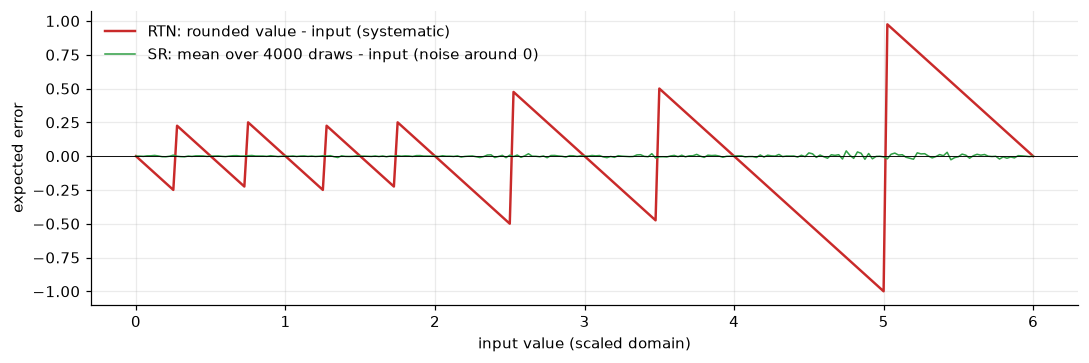

PASS - SR: |mean error| < 4 sigma = 0.064 everywhere (unbiased up to sampling noise) | max 0.0390
PASS - RTN: errors reach +-0.5 (the bias SR removes) 

sum of 1000 x 0.2 = 200 | after RTN each: 0.0 | after SR each: 196.5
PASS - RTN erases a consistently small gradient (sum 0 instead of 200); SR keeps it (~200) 


In [6]:
gen = torch.Generator().manual_seed(0)
fwd = k.round_fp4(torch.tensor(5.4 / 9.0)).item() * 9.0
print("forward: 5.4 / 9 = 0.6 ->", fwd / 9.0, "-> x 9 =", fwd)
draws = k.round_fp4(torch.full((400_000,), fwd / 2.0), "sr", gen) * 2.0
vals, counts = draws.unique(return_counts=True)
print("backward SR of", fwd, "in a scale-2 block:", {float(v): round(float(c) / len(draws), 3) for v, c in zip(vals, counts)}, "-> mean", round(draws.mean().item(), 4))
rtn = k.round_fp4(torch.tensor(fwd / 2.0)).item() * 2.0
print("backward RTN gives", rtn, "every time (bias", rtn - fwd, ")")
check("SR example from the post: mean of backward values = 4.5", abs(draws.mean().item() - 4.5) < 0.01)
check("RTN on the same value is biased (always 4.0)", rtn == 4.0)

# bias of RTN vs SR as a function of the input value
xs = torch.linspace(0, 6, 241)
mean_sr = torch.stack([k.round_fp4(x.repeat(4000), "sr", gen).mean() for x in xs])
bias_rtn = k.round_fp4(xs) - xs
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(xs, bias_rtn, color=BAD_C, lw=1.6, label="RTN: rounded value - input (systematic)")
ax.plot(xs, mean_sr - xs, color=NV_C, lw=1.0, label="SR: mean over 4000 draws - input (noise around 0)")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("input value (scaled domain)"); ax.set_ylabel("expected error"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
# sampling noise: the widest FP4 gap is 2 (between 4 and 6), so one SR draw has std <= 1.0 and the mean of 4000 draws has std <= 1/sqrt(4000) = 0.016; over 241 points the max is ~3 sigma
check("SR: |mean error| < 4 sigma = 0.064 everywhere (unbiased up to sampling noise)", (mean_sr - xs).abs().max().item() < 4 / math.sqrt(4000), f"max {(mean_sr - xs).abs().max():.4f}")
check("RTN: errors reach +-0.5 (the bias SR removes)", bias_rtn.abs().max().item() >= 0.5)

# why bias hurts: add many small increments, as gradient accumulation does
tiny = torch.full((1000,), 0.2)                   # 1000 identical small gradient values
print(f"\nsum of 1000 x 0.2 = 200 | after RTN each: {k.round_fp4(tiny).sum():.1f} | after SR each: {k.round_fp4(tiny, 'sr', gen).sum():.1f}")
check("RTN erases a consistently small gradient (sum 0 instead of 200); SR keeps it (~200)", k.round_fp4(tiny).sum().item() == 0 and abs(k.round_fp4(tiny, "sr", gen).sum().item() - 200) < 20)

Two properties follow, and both appear in the sources: SR is **needed for gradients** (small consistent values must survive), but it **hurts the forward pass** because it adds noise on top of the rounding error (NVIDIA: "applying stochastic rounding to the forward pass tensors is detrimental"). So the recipe uses RTN (with 4/6) forward and SR backward.

## Step 5 - The transpose problem

A linear layer `y = x · Wᵀ` has two backward products:
`dx = g · W` (contracts over the *output* dimension N) and `dW = gᵀ · x` (contracts over the *token* dimension T).
Block scaling must group values **along the axis being contracted**, so the forward pass blocks `W` along K, while the backward pass needs `W` blocked along N. Different blocks → different scales → **different quantized values** for the same weight.

In [7]:
torch.manual_seed(3)
W = torch.randn(128, 128) * torch.exp(0.7 * torch.randn(128, 1))            # rows (output channels) with different scales
Wq = k.quantize_nvfp4(W).dequantize()                                        # forward: blocks of 16 along K (within a row)
W_blocks_along_N = k.quantize_nvfp4(W.t().contiguous()).dequantize().t()     # what a backward kernel gets if it re-quantizes W along N
differ = (Wq != W_blocks_along_N).float().mean().item()
print(f"fraction of weights whose quantized value differs between forward and backward blocking: {differ:.1%}")
print(f"relative difference ||Wq_fwd - Wq_bwd|| / ||W||: {((Wq - W_blocks_along_N).norm() / W.norm()).item():.4f}")
check("blocking along K vs along N quantizes >30% of the weights differently", differ > 0.30, f"{differ:.1%}")

fraction of weights whose quantized value differs between forward and backward blocking: 82.3%
relative difference ||Wq_fwd - Wq_bwd|| / ||W||: 0.1302
PASS - blocking along K vs along N quantizes >30% of the weights differently | 82.3%


**Option A - NVIDIA's 2D scaling:** one scale per **16 × 16 tile**, so the quantized weight is *identical* whichever axis you block along. The post tried this ("NVIDIA's suggestion") and found it "too coarse, hurting CE beyond what we were willing to accept". Here is the coarseness, measured:

In [8]:
W2 = k.quantize_nvfp4_2d(W)
print(f"2D tile scaling is transpose-invariant: {torch.equal(k.quantize_nvfp4_2d(W.t().contiguous()), W2.t())}")
mse1, mse2 = rel_mse(Wq, W), rel_mse(W2, W)
print(f"error energy: 1x16 blocks {mse1:.3e} | 16x16 tiles {mse2:.3e}  ({mse2 / mse1:.2f}x)")

# the outlier case: one huge value in a 32x32 matrix of N(0,1)
torch.manual_seed(5)
A = torch.randn(32, 32); A[5, 5] = 500.0
nz = lambda t: int((t[:16, :16] != 0).sum())
base = nz(k.quantize_nvfp4(torch.randn(32, 32)).dequantize())
n1, n2 = nz(k.quantize_nvfp4(A).dequantize()), nz(k.quantize_nvfp4_2d(A))
print(f"non-zero values in the 16x16 tile that holds the outlier:  no outlier {base}/256 | 1x16 blocks {n1}/256 | 16x16 tiles {n2}/256")
check("2D tile scaling gives the same quantized weight in forward and transposed use", torch.equal(k.quantize_nvfp4_2d(W.t().contiguous()), W2.t()))
check("16x16 tiles have higher error than 1x16 blocks (>=1.2x here)", mse2 / mse1 >= 1.2, f"{mse2 / mse1:.2f}x")
check("one outlier wipes out its whole 16x16 tile (only the outlier survives) but only its 16-block with 1x16", n2 == 1 and 200 < n1 < 256, f"{n1} vs {n2}")

2D tile scaling is transpose-invariant: True
error energy: 1x16 blocks 8.628e-03 | 16x16 tiles 2.236e-02  (2.59x)
non-zero values in the 16x16 tile that holds the outlier:  no outlier 240/256 | 1x16 blocks 231/256 | 16x16 tiles 1/256
PASS - 2D tile scaling gives the same quantized weight in forward and transposed use 
PASS - 16x16 tiles have higher error than 1x16 blocks (>=1.2x here) | 2.59x
PASS - one outlier wipes out its whole 16x16 tile (only the outlier survives) but only its 16-block with 1x16 | 231 vs 1


**Option B - the post's fix:** keep fine 1×16 blocks and do not require the forward and backward weights to be *bitwise* equal. Require them to be **equal in expectation**:

> `E[ w_q ] = E[ (w_qᵀ)_q ]` - dequantize the forward tensor, transpose it in high precision, re-quantize with **stochastic rounding** (blocks now along N).

SR is unbiased, so averaged over many draws the re-quantized weight returns exactly the forward weight. Check this, and compare with deterministic (RTN) re-quantization:

In [9]:
Wt = Wq.t().contiguous()                                    # dequantized forward weight, transposed in high precision, blocks along N
gen = torch.Generator().manual_seed(1)
def requant(kind, rounding):
    if kind == "mxfp8": return k.quantize_mx(Wt, "mxfp8", rounding=rounding, gen=gen if rounding == "sr" else None)
    return k.quantize_nvfp4(Wt, rounding=rounding, gen=gen if rounding == "sr" else None).dequantize()
rel = lambda a: ((a - Wt).norm() / Wt.norm()).item()
out = {}
for kind in ("mxfp8", "nvfp4"):
    single = rel(requant(kind, "sr"))
    mean_sr = torch.stack([requant(kind, "sr") for _ in range(400)]).mean(0)
    out[kind] = (single, rel(mean_sr), rel(requant(kind, "rtn")))
    print(f"{kind:6s} re-quantization error vs forward weight:  1 SR draw {out[kind][0]:.4f} | mean of 400 SR draws {out[kind][1]:.4f} | RTN (fixed) {out[kind][2]:.4f}")
check("mean of SR re-quantizations converges to the forward weight (error falls >10x)", all(v[1] < v[0] / 10 for v in out.values()))
check("RTN re-quantization has a fixed error floor that averaging cannot remove (NVFP4: > 3x the SR mean)", out["nvfp4"][2] > 3 * out["nvfp4"][1])

mxfp8  re-quantization error vs forward weight:  1 SR draw 0.0377 | mean of 400 SR draws 0.0018 | RTN (fixed) 0.0276


nvfp4  re-quantization error vs forward weight:  1 SR draw 0.1290 | mean of 400 SR draws 0.0088 | RTN (fixed) 0.0898
PASS - mean of SR re-quantizations converges to the forward weight (error falls >10x) 
PASS - RTN re-quantization has a fixed error floor that averaging cannot remove (NVFP4: > 3x the SR mean) 


The post re-quantizes to **MXFP8** (not NVFP4): one SR draw is already ≈ 10× closer to the forward weight than an NVFP4 re-quantization, and averaging removes the rest.

## Step 6 - The recipe as one layer

Putting the pieces together for one linear layer (`T` tokens, `K` inputs, `N` outputs). Green = NVFP4, orange = MXFP8, grey = high precision (the forward quantized tensors are saved and later de-quantized in high precision):

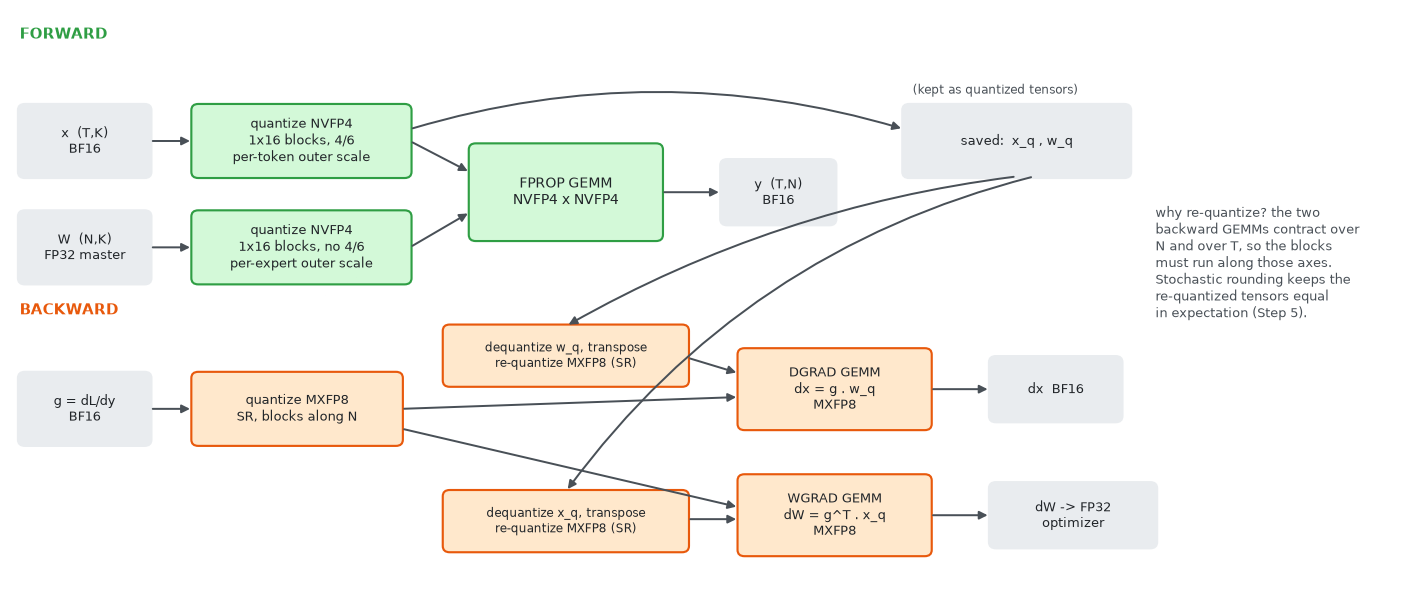

In [10]:
def box(ax, x, y, w, h, text, fc, ec=None, fs=8.5, tc="#212529"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec or fc, lw=1.4)); ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc)
def arrow(ax, a, b, **kw): ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=11, lw=1.3, color="#495057", **kw))
LG, LN, LO = "#e9ecef", "#d3f9d8", "#ffe8cc"
fig, ax = plt.subplots(figsize=(13, 5.6)); ax.set_xlim(0, 16); ax.set_ylim(0, 7.4); ax.axis("off")
ax.text(0.1, 7.05, "FORWARD", fontweight="bold", color=NV_C); ax.text(0.1, 3.55, "BACKWARD", fontweight="bold", color=MX_C)
box(ax, 0.1, 5.3, 1.5, 0.9, "x  (T,K)\nBF16", LG); box(ax, 2.1, 5.3, 2.5, 0.9, "quantize NVFP4\n1x16 blocks, 4/6\nper-token outer scale", LN, NV_C)
box(ax, 0.1, 3.95, 1.5, 0.9, "W  (N,K)\nFP32 master", LG); box(ax, 2.1, 3.95, 2.5, 0.9, "quantize NVFP4\n1x16 blocks, no 4/6\nper-expert outer scale", LN, NV_C)
box(ax, 5.3, 4.5, 2.2, 1.2, "FPROP GEMM\nNVFP4 x NVFP4", LN, NV_C, fs=9); box(ax, 8.2, 4.7, 1.3, 0.8, "y  (T,N)\nBF16", LG)
arrow(ax, (1.6, 5.75), (2.1, 5.75)); arrow(ax, (1.6, 4.4), (2.1, 4.4)); arrow(ax, (4.6, 5.75), (5.3, 5.35)); arrow(ax, (4.6, 4.4), (5.3, 4.85)); arrow(ax, (7.5, 5.1), (8.2, 5.1))
box(ax, 10.3, 5.3, 2.6, 0.9, "saved:  x_q , w_q", LG); arrow(ax, (4.6, 5.9), (10.3, 5.9), connectionstyle="arc3,rad=-0.15")
ax.text(10.4, 6.35, "(kept as quantized tensors)", fontsize=8, color=HP_C)
box(ax, 0.1, 1.9, 1.5, 0.9, "g = dL/dy\nBF16", LG); box(ax, 2.1, 1.9, 2.4, 0.9, "quantize MXFP8\nSR, blocks along N", LO, MX_C)
box(ax, 5.0, 2.65, 2.8, 0.75, "dequantize w_q, transpose\nre-quantize MXFP8 (SR)", LO, MX_C, fs=8)
box(ax, 5.0, 0.55, 2.8, 0.75, "dequantize x_q, transpose\nre-quantize MXFP8 (SR)", LO, MX_C, fs=8)
box(ax, 8.4, 2.1, 2.2, 1.0, "DGRAD GEMM\ndx = g . w_q\nMXFP8", LO, MX_C); box(ax, 8.4, 0.5, 2.2, 1.0, "WGRAD GEMM\ndW = g^T . x_q\nMXFP8", LO, MX_C)
box(ax, 11.3, 2.2, 1.5, 0.8, "dx  BF16", LG); box(ax, 11.3, 0.6, 1.9, 0.8, "dW -> FP32\noptimizer", LG)
arrow(ax, (1.6, 2.35), (2.1, 2.35)); arrow(ax, (4.5, 2.35), (8.4, 2.5)); arrow(ax, (4.5, 2.1), (8.4, 1.1))
arrow(ax, (7.8, 3.0), (8.4, 2.8)); arrow(ax, (7.8, 0.95), (8.4, 0.95)); arrow(ax, (10.6, 2.6), (11.3, 2.6)); arrow(ax, (10.6, 1.0), (11.3, 1.0))
arrow(ax, (11.6, 5.3), (6.4, 3.4), connectionstyle="arc3,rad=0.1"); arrow(ax, (11.8, 5.3), (6.4, 1.3), connectionstyle="arc3,rad=0.18")
ax.text(13.2, 4.2, "why re-quantize? the two\nbackward GEMMs contract over\nN and over T, so the blocks\nmust run along those axes.\nStochastic rounding keeps the\nre-quantized tensors equal\nin expectation (Step 5).", fontsize=8.5, color=HP_C, va="center")
plt.tight_layout(); plt.show()

`fp4kit.fp4_linear` implements exactly this. Three checks on one layer with realistic outlier channels in the activations:

1. the forward output stays close to the fp32 output;
2. a **single** backward pass has noise (SR), but the **average over many passes converges** to the gradient of the *quantized* forward (`g·w_q`, `gᵀ·x_q`) - i.e. the backward is unbiased given the forward;
3. deterministic (RTN) re-quantization instead of SR leaves a **bias that does not average out**.

forward: relative error of y = 0.1276
PASS - forward output within 15% of fp32 (relative norm error) 


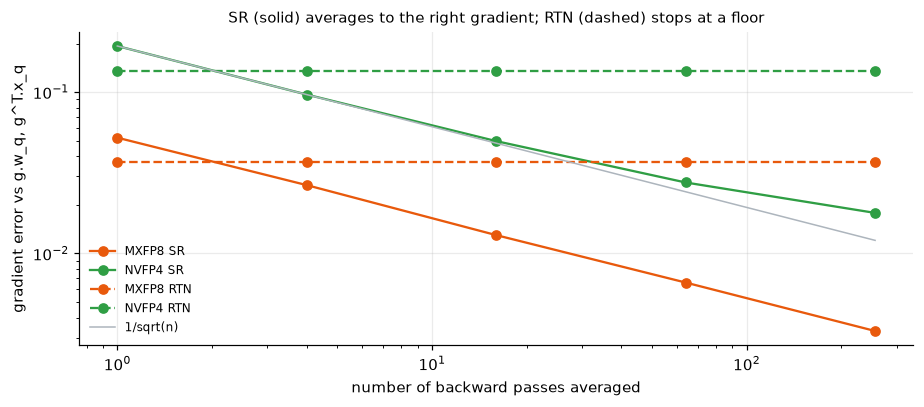

mxfp8_sr   error after 1 pass 0.0522 -> after 256 passes 0.0033
nvfp4_sr   error after 1 pass 0.1929 -> after 256 passes 0.0178
mxfp8_rtn  error after 1 pass 0.0368 -> after 256 passes 0.0368
nvfp4_rtn  error after 1 pass 0.1350 -> after 256 passes 0.1350
PASS - SR gradient error falls >8x when averaging 256 passes (unbiased) 
PASS - RTN re-quantization plateaus: averaging 256 passes does not help (error stays > 0.5x of one pass) | 0.1350 -> 0.1350
PASS - single MXFP8-SR backward is ~3x more accurate than a single NVFP4-SR backward | 0.193 vs 0.052


In [11]:
torch.manual_seed(7)
T, K, N = 256, 256, 256
x = torch.randn(T, K) * (1 + 9 * (torch.rand(1, K) < 0.03))               # a few outlier channels, as in real activations
w = torch.randn(N, K) / math.sqrt(K); g = torch.randn(T, N) * 0.01

cfg = k.RecipeConfig()
xq = k.quantize_nvfp4(x, four_over_six=True, outer="row").dequantize(); wq = k.quantize_nvfp4(w).dequantize()
y_ref, y_q = x @ w.t(), k.fp4_linear(x, w, cfg)
print(f"forward: relative error of y = {((y_q - y_ref).norm() / y_ref.norm()).item():.4f}")
check("forward output within 15% of fp32 (relative norm error)", ((y_q - y_ref).norm() / y_ref.norm()).item() < 0.15)
dx_t, dw_t = g @ wq, g.t() @ xq                                              # the exact gradient of the quantized forward
dx_fp, dw_fp = g @ w, g.t() @ x                                              # fp32 gradients

def grads(bwd):
    xr, wr = x.clone().requires_grad_(), w.clone().requires_grad_()
    k.fp4_linear(xr, wr, k.RecipeConfig(bwd=bwd)).backward(g); return xr.grad, wr.grad
err = lambda a, b: ((a - b).norm() / b.norm()).item()
ns = [1, 4, 16, 64, 256]
curves = {}
for bwd in ("mxfp8_sr", "nvfp4_sr", "mxfp8_rtn", "nvfp4_rtn"):
    acc_dx = torch.zeros_like(dx_t); acc_dw = torch.zeros_like(dw_t); c = []
    for n in range(1, max(ns) + 1):
        a, b = grads(bwd); acc_dx += a; acc_dw += b
        if n in ns: c.append((err(acc_dx / n, dx_t) + err(acc_dw / n, dw_t)) / 2)
    curves[bwd] = c
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sty = {"mxfp8_sr": (MX_C, "-"), "nvfp4_sr": (NV_C, "-"), "mxfp8_rtn": (MX_C, "--"), "nvfp4_rtn": (NV_C, "--")}
for bwd, c in curves.items(): ax.loglog(ns, c, marker="o", color=sty[bwd][0], ls=sty[bwd][1], label=bwd.replace("_", " ").upper())
ax.loglog(ns, [curves["nvfp4_sr"][0] / math.sqrt(n) for n in ns], color="#adb5bd", lw=1, label="1/sqrt(n)")
ax.set_xlabel("number of backward passes averaged"); ax.set_ylabel("gradient error vs g.w_q, g^T.x_q"); ax.legend(frameon=False, fontsize=8)
ax.set_title("SR (solid) averages to the right gradient; RTN (dashed) stops at a floor", fontsize=10); plt.tight_layout(); plt.show()
for bwd, c in curves.items(): print(f"{bwd:10s} error after 1 pass {c[0]:.4f} -> after 256 passes {c[-1]:.4f}")
check("SR gradient error falls >8x when averaging 256 passes (unbiased)", all(curves[b][-1] < curves[b][0] / 8 for b in ("mxfp8_sr", "nvfp4_sr")))
check("RTN re-quantization plateaus: averaging 256 passes does not help (error stays > 0.5x of one pass)", curves["nvfp4_rtn"][-1] > 0.5 * curves["nvfp4_rtn"][0], f"{curves['nvfp4_rtn'][0]:.4f} -> {curves['nvfp4_rtn'][-1]:.4f}")
check("single MXFP8-SR backward is ~3x more accurate than a single NVFP4-SR backward", curves["nvfp4_sr"][0] > 2.0 * curves["mxfp8_sr"][0], f"{curves['nvfp4_sr'][0]:.3f} vs {curves['mxfp8_sr'][0]:.3f}")

Read the plot carefully: per pass, RTN is actually *closer* (MXFP8-RTN 0.037 vs MXFP8-SR 0.052 here) - but its error is a fixed bias, while SR's error is noise that averages away (0.0033 after 256 passes, 10× below the RTN floor). NVFP4-SR departs slightly from the 1/√n line at large n; a plausible cause is saturation when the E4M3-rounded block scale pushes a block maximum above 6 (not investigated here).

This is the quantitative reason for the post's design: the backward needs **many small, unbiased** contributions; MXFP8 gives much less noise per pass than NVFP4 for the same unbiasedness, so the post keeps the backward in MXFP8 and uses NVFP4 only where RTN is acceptable (forward).

## Step 7 - Does a small transformer train with it?

A 2-block causal transformer (d = 128, 4 heads, MLP 256, 0.4 M parameters) on text from a **random order-2 Markov chain** over 24 symbols. The data has a known **entropy floor** (the best possible loss), so "how close to the floor" is measurable. Only the four linear layers per block are quantized (`qkv`, attention output, both MLP layers) - the post also quantizes only the MoE expert linears; embeddings, norms, attention and the output head stay in fp32. Optimizer: AdamW on fp32 master weights. Fresh data every step (no memorization), 2 seeds.

In [12]:
V = 24
torch.manual_seed(0)
P = torch.distributions.Dirichlet(torch.full((V,), 0.15)).sample((V * V,))          # P[a*V+b] = next-token distribution after (a, b)
def sample_batch(B, T, gen):
    out = torch.zeros(B, T + 1, dtype=torch.long)
    out[:, 0] = torch.randint(0, V, (B,), generator=gen); out[:, 1] = torch.randint(0, V, (B,), generator=gen)
    for t in range(2, T + 1):
        out[:, t] = torch.multinomial(P[out[:, t - 2] * V + out[:, t - 1]], 1, generator=gen).squeeze(1)
    return out
big = sample_batch(4000, 64, torch.Generator().manual_seed(7))
FLOOR = -(torch.log(P[big[:, :-2] * V + big[:, 1:-1], big[:, 2:]].clamp(min=1e-12))).mean().item()
print(f"entropy floor (best achievable loss): {FLOOR:.4f} nats   | uniform guess: {math.log(V):.4f}")

class Block(nn.Module):
    def __init__(s, d, h, ff, cfg):
        super().__init__(); s.h = h; s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.qkv, s.o = k.Fp4Linear(d, 3 * d, cfg), k.Fp4Linear(d, d, cfg); s.f1, s.f2 = k.Fp4Linear(d, ff, cfg), k.Fp4Linear(ff, d, cfg)
    def forward(s, x):
        B, T, D = x.shape; q, kk, v = s.qkv(s.n1(x)).chunk(3, -1)
        sp = lambda t: t.view(B, T, s.h, D // s.h).transpose(1, 2)
        a = F.scaled_dot_product_attention(sp(q), sp(kk), sp(v), is_causal=True).transpose(1, 2).reshape(B, T, D)
        x = x + s.o(a); return x + s.f2(F.gelu(s.f1(s.n2(x))))
class LM(nn.Module):
    def __init__(s, cfgs, d=128, h=4, ff=256, T=64):
        super().__init__(); s.emb, s.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        s.blocks = nn.ModuleList([Block(d, h, ff, c) for c in cfgs]); s.nf = nn.LayerNorm(d); s.head = nn.Linear(d, V)
    def forward(s, x):
        h = s.emb(x) + s.pos(torch.arange(x.shape[1], device=x.device))
        for b in s.blocks: h = b(h)
        return s.head(s.nf(h))

def train(cfgs, seed, steps=800, B=32, T=64, lr=4e-3, device="cpu"):
    torch.manual_seed(seed); m = LM(cfgs).to(device); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.0)
    gen = torch.Generator().manual_seed(100 + seed); losses = []
    for s_ in range(steps):
        d = sample_batch(B, T, gen).to(device)
        for gp in opt.param_groups: gp["lr"] = lr * min(1, (s_ + 1) / 30) * (0.9 * 0.5 * (1 + math.cos(math.pi * s_ / steps)) + 0.1)
        loss = F.cross_entropy(m(d[:, :-1]).reshape(-1, V), d[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); losses.append(loss.item())
    ev = sample_batch(256, T, torch.Generator().manual_seed(999)).to(device)
    with torch.no_grad(): ev_loss = F.cross_entropy(m(ev[:, :-1]).reshape(-1, V), ev[:, 1:].reshape(-1)).item()
    return np.array(losses), ev_loss

CONFIGS = {
    "fp32 reference":                          k.RecipeConfig(fwd="none", bwd="none"),
    "NVFP4 fwd, fp32 bwd":                     k.RecipeConfig(fwd="nvfp4", bwd="none"),
    "recipe: NVFP4 fwd + MXFP8-SR bwd":        k.RecipeConfig(),
    "recipe without 4/6":                      k.RecipeConfig(act_four_over_six=False),
    "all NVFP4 (fwd + NVFP4-SR bwd)":          k.RecipeConfig(bwd="nvfp4_sr"),
}
RES = {}
def run_config(name, seeds=(0, 1)):
    t0 = time.time()
    for s_ in seeds:
        c = CONFIGS[name]; RES[(name, s_)] = train([c, c], s_)
    ev = [RES[(name, s_)][1] for s_ in seeds]
    print(f"{name:36s} eval loss {np.mean(ev):.4f}  (gap to floor {np.mean(ev) - FLOOR:+.4f})  seeds {[round(e, 4) for e in ev]}  [{time.time() - t0:.0f}s]")
run_config("fp32 reference")

entropy floor (best achievable loss): 1.7773 nats   | uniform guess: 3.1781


fp32 reference                       eval loss 1.8720  (gap to floor +0.0946)  seeds [1.8746, 1.8693]  [14s]


In [13]:
run_config("NVFP4 fwd, fp32 bwd")
run_config("recipe: NVFP4 fwd + MXFP8-SR bwd")

NVFP4 fwd, fp32 bwd                  eval loss 1.8951  (gap to floor +0.1178)  seeds [1.8985, 1.8918]  [56s]


recipe: NVFP4 fwd + MXFP8-SR bwd     eval loss 1.8978  (gap to floor +0.1205)  seeds [1.8999, 1.8958]  [133s]


In [14]:
run_config("recipe without 4/6")
run_config("all NVFP4 (fwd + NVFP4-SR bwd)")

recipe without 4/6                   eval loss 1.9017  (gap to floor +0.1244)  seeds [1.9011, 1.9023]  [112s]


all NVFP4 (fwd + NVFP4-SR bwd)       eval loss 1.9004  (gap to floor +0.1231)  seeds [1.9021, 1.8987]  [222s]


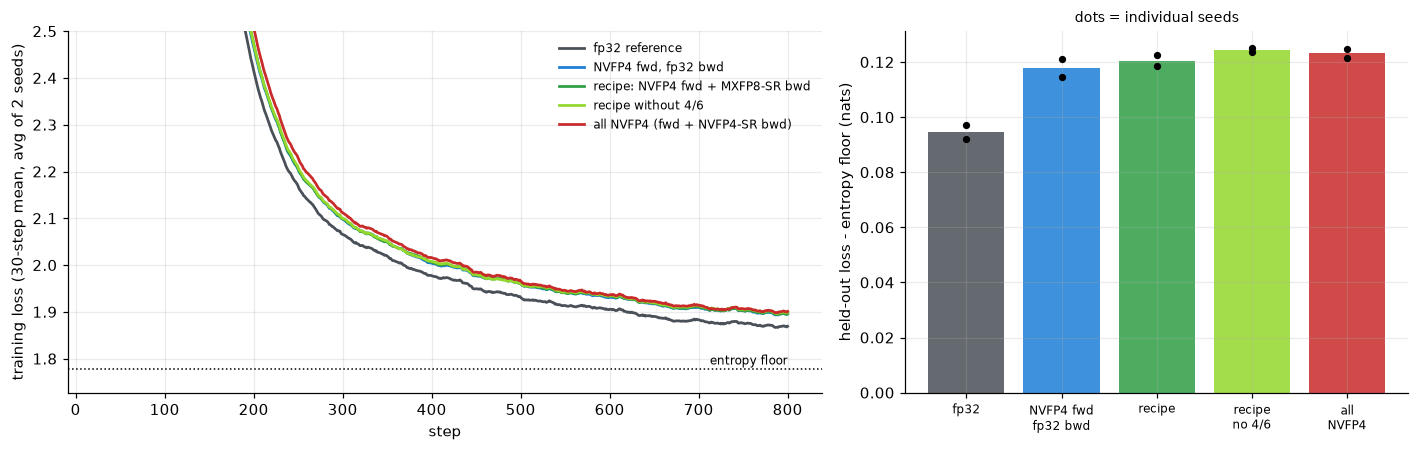

fp32 reference                       gap to floor +0.0946 nats   (+0.0000 vs fp32)
NVFP4 fwd, fp32 bwd                  gap to floor +0.1178 nats   (+0.0232 vs fp32)
recipe: NVFP4 fwd + MXFP8-SR bwd     gap to floor +0.1205 nats   (+0.0259 vs fp32)
recipe without 4/6                   gap to floor +0.1244 nats   (+0.0297 vs fp32)
all NVFP4 (fwd + NVFP4-SR bwd)       gap to floor +0.1231 nats   (+0.0285 vs fp32)
largest seed-to-seed difference within one configuration: 0.0067 nats
PASS - every 4-bit configuration is worse than fp32 by a small but measurable amount (0.005-0.08 nats) | +0.023 / +0.026 / +0.030 / +0.028
PASS - the four 4-bit configurations are within 0.02 nats of each other (their ordering is not resolved at this scale) | range 0.0065
PASS - fp32 reference gets within 0.2 nats of the entropy floor | 0.095
PASS - 'NVFP4 fwd, fp32 bwd' trains (final train loss < 60% of the start) 
PASS - 'recipe: NVFP4 fwd + MXFP8-SR bwd' trains (final train loss < 60% of the start) 
PASS - 

In [15]:
names = list(CONFIGS)
col = {"fp32 reference": HP_C, "NVFP4 fwd, fp32 bwd": INT_C, "recipe: NVFP4 fwd + MXFP8-SR bwd": NV_C, "recipe without 4/6": "#94d82d", "all NVFP4 (fwd + NVFP4-SR bwd)": BAD_C}
sm = lambda a, w=30: np.convolve(a, np.ones(w) / w, mode="valid")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for n in names:
    curve = np.mean([RES[(n, s_)][0] for s_ in (0, 1)], 0)
    axs[0].plot(np.arange(len(sm(curve))) + 30, sm(curve), color=col[n], lw=1.8, label=n)
axs[0].axhline(FLOOR, color="k", ls=":", lw=1); axs[0].text(800, FLOOR + 0.01, "entropy floor", ha="right", fontsize=8)
axs[0].set_ylim(FLOOR - 0.05, 2.5); axs[0].set_xlabel("step"); axs[0].set_ylabel("training loss (30-step mean, avg of 2 seeds)"); axs[0].legend(frameon=False, fontsize=8)
for i, n in enumerate(names):
    ev = [RES[(n, s_)][1] - FLOOR for s_ in (0, 1)]
    axs[1].bar(i, np.mean(ev), color=col[n], alpha=0.85); axs[1].scatter([i, i], ev, color="k", s=14, zorder=3)
axs[1].set_xticks(range(len(names))); axs[1].set_xticklabels(["fp32", "NVFP4 fwd\nfp32 bwd", "recipe", "recipe\nno 4/6", "all\nNVFP4"], fontsize=8)
axs[1].set_ylabel("held-out loss - entropy floor (nats)"); axs[1].set_title("dots = individual seeds", fontsize=9)
plt.tight_layout(); plt.show()

gap = {n: np.mean([RES[(n, s_)][1] for s_ in (0, 1)]) - FLOOR for n in names}
for n in names: print(f"{n:36s} gap to floor {gap[n]:+.4f} nats   ({gap[n] - gap['fp32 reference']:+.4f} vs fp32)")
spread = max(abs(RES[(n, 0)][1] - RES[(n, 1)][1]) for n in names)
print(f"largest seed-to-seed difference within one configuration: {spread:.4f} nats")
q4 = [gap[n] - gap["fp32 reference"] for n in names[1:]]
check("every 4-bit configuration is worse than fp32 by a small but measurable amount (0.005-0.08 nats)", all(0.005 < d < 0.08 for d in q4), " / ".join(f"{d:+.3f}" for d in q4))
check("the four 4-bit configurations are within 0.02 nats of each other (their ordering is not resolved at this scale)", max(q4) - min(q4) < 0.02, f"range {max(q4) - min(q4):.4f}")
check("fp32 reference gets within 0.2 nats of the entropy floor", gap["fp32 reference"] < 0.2, f"{gap['fp32 reference']:.3f}")
for n in names[1:]: check(f"'{n}' trains (final train loss < 60% of the start)", all(RES[(n, s_)][0][-30:].mean() < 0.6 * RES[(n, s_)][0][:5].mean() for s_ in (0, 1)))

**How to read this.** The measured gaps are the result - the table above prints them with the seed spread. At this scale (0.4 M parameters, 800 steps) differences between the quantized configurations can be comparable to the seed-to-seed spread, so this experiment supports statements of the form *"the recipe trains and tracks fp32 closely here"*; it **cannot** reproduce the post's reported ≈ 2 % compute-efficiency cost at 10⁹-10¹¹ scale, and it does not decide whether 4/6 or the MXFP8 backward is worth it at scale (the numerical evidence for those is Steps 3 and 6).

## Step 8 - Quantized communication: RHT + S2F6

In expert parallelism every token's expert output must cross NVLink ("combine"). The post wants fewer than 16 bits per value but found plain MXFP8 hurt quality "because of poor outlier handling". Its fix: a **32-dim random Hadamard transform (RHT)**, then **S2F6** (an 8-bit signed fixed-point format: 2 integer bits, 6 fractional bits, range −128/64 … 127/64) with one scale per 32 values → `8 + 8/32 = 8.25` bits/value instead of 16.

An RHT is an orthogonal rotation: it preserves total energy, is exactly invertible, and spreads one large value across all 32 slots, so no single value dominates the block scale. (The post gives no scale rule for S2F6; the kit chooses the smallest power of two that fits the block maximum.)

energy before 64.5400  after RHT 64.5400  | max |value|: 8.00 -> 1.66
exactly invertible: True
PASS - RHT preserves energy and is invertible 


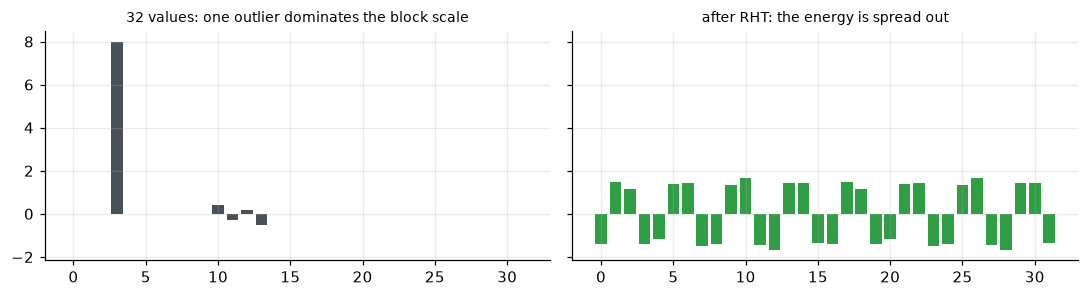

                                 MXFP8 (E4M3, E8M0/32)                      S2F6                RHT + S2F6
Gaussian                                      7.05e-04                  6.89e-05                  6.91e-05
with outliers (0.3% x60)                      7.04e-04                  3.28e-04                  1.93e-05


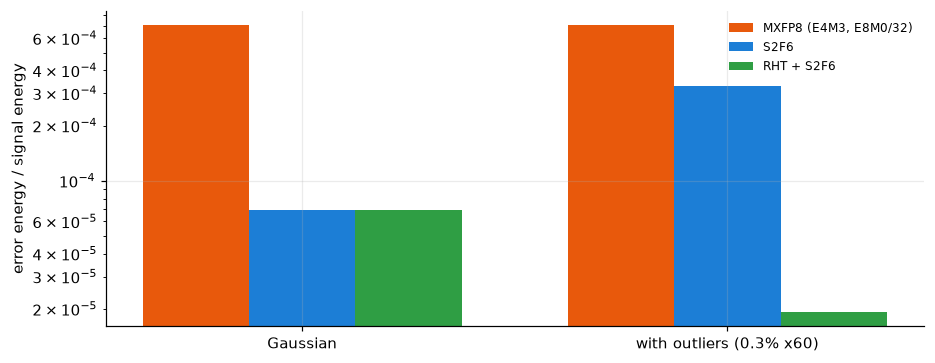

PASS - all three are 8.25 bits/value (E8M0 scale per 32): same traffic 
PASS - on well-behaved data S2F6 is ~10x more accurate than MXFP8 at the same size | 10.2x
PASS - outliers hurt plain S2F6 (>3x worse) ... | 4.8x
PASS - ... and RHT repairs it (RHT+S2F6 on outlier data >5x better than S2F6, and better than MXFP8) | 17.0x


In [16]:
rht = k.RandomHadamard(32, seed=0)
v = torch.zeros(1, 32); v[0, 3] = 8.0; v[0, 10:14] = torch.tensor([0.4, -0.3, 0.2, -0.5])        # one big value, a few small ones
y = rht.forward(v)
print(f"energy before {v.pow(2).sum():.4f}  after RHT {y.pow(2).sum():.4f}  | max |value|: {v.abs().max():.2f} -> {y.abs().max():.2f}")
print("exactly invertible:", torch.allclose(rht.inverse(y), v, atol=1e-5))
check("RHT preserves energy and is invertible", torch.allclose(y.pow(2).sum(), v.pow(2).sum(), rtol=1e-5) and torch.allclose(rht.inverse(y), v, atol=1e-5))
fig, axs = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
axs[0].bar(range(32), v[0], color=HP_C); axs[0].set_title("32 values: one outlier dominates the block scale", fontsize=9)
axs[1].bar(range(32), y[0], color=NV_C); axs[1].set_title("after RHT: the energy is spread out", fontsize=9)
plt.tight_layout(); plt.show()

torch.manual_seed(2)
D = {"Gaussian": torch.randn(2048, 2048), "with outliers (0.3% x60)": torch.randn(2048, 2048) * (1 + 60 * (torch.rand(2048, 2048) < 0.003))}
M = {"MXFP8 (E4M3, E8M0/32)": lambda t: k.quantize_mx(t, "mxfp8"), "S2F6": lambda t: k.quantize_s2f6(t), "RHT + S2F6": lambda t: rht.inverse(k.quantize_s2f6(rht.forward(t)))}
R2 = {d: {m: rel_mse(f(t), t) for m, f in M.items()} for d, t in D.items()}
print(f"{'':28s}" + "".join(f"{m:>26s}" for m in M))
for d in R2: print(f"{d:28s}" + "".join(f"{R2[d][m]:26.2e}" for m in M))
fig, ax = plt.subplots(figsize=(8.6, 3.4)); w = 0.25
for i, (m, c) in enumerate(zip(M, [MX_C, INT_C, NV_C])): ax.bar(np.arange(2) + (i - 1) * w, [R2[d][m] for d in R2], w, color=c, label=m)
ax.set_yscale("log"); ax.set_xticks(range(2)); ax.set_xticklabels(list(R2)); ax.set_ylabel("error energy / signal energy"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
g_, o_ = R2["Gaussian"], R2["with outliers (0.3% x60)"]
check("all three are 8.25 bits/value (E8M0 scale per 32): same traffic", k.bits_per_value(8, 8, 32) == 8.25)
check("on well-behaved data S2F6 is ~10x more accurate than MXFP8 at the same size", g_["S2F6"] * 5 < g_["MXFP8 (E4M3, E8M0/32)"], f"{g_['MXFP8 (E4M3, E8M0/32)'] / g_['S2F6']:.1f}x")
check("outliers hurt plain S2F6 (>3x worse) ...", o_["S2F6"] > 3 * g_["S2F6"], f"{o_['S2F6'] / g_['S2F6']:.1f}x")
check("... and RHT repairs it (RHT+S2F6 on outlier data >5x better than S2F6, and better than MXFP8)", o_["RHT + S2F6"] * 5 < o_["S2F6"] and o_["RHT + S2F6"] < o_["MXFP8 (E4M3, E8M0/32)"], f"{o_['S2F6'] / o_['RHT + S2F6']:.1f}x")

The measurement agrees with the post's story *as an error measurement*: with the same 8.25 bits, S2F6 beats MXFP8 on ordinary data, loses its advantage when outliers set the block scale, and the RHT restores it. Whether this leaves "no measurable accuracy degradation during training" (the post's claim) is a large-model training result that is not tested here.

## Step 9 - Does it run on this Mac?

Three levels of evidence: (1) the same quantizers give **identical results on the CPU and on the Apple GPU (mps)**; (2) the repo's unit tests for `fp4kit` pass; (3) a short training run works on the Apple GPU.

In [17]:
print("platform:", sys.platform, "| torch", torch.__version__, "| mps available:", torch.backends.mps.is_available(), "| built:", torch.backends.mps.is_built())
if torch.backends.mps.is_available():
    torch.manual_seed(0); xx = torch.randn(512, 512)
    fns = {"round_fp4 (RTN)": lambda t: k.round_fp4(t * 3), "round_e4m3": lambda t: k.round_e4m3(t * 100), "NVFP4": lambda t: k.quantize_nvfp4(t).dequantize(),
           "NVFP4 + 4/6 (per-token)": lambda t: k.quantize_nvfp4(t, four_over_six=True, outer="row").dequantize(), "MXFP8": lambda t: k.quantize_mx(t, "mxfp8"),
           "S2F6": lambda t: k.quantize_s2f6(t), "RHT round trip": lambda t: rht.inverse(rht.forward(t))}
    for n, f in fns.items():
        a, b = f(xx), f(xx.to("mps")).cpu()
        same = torch.equal(a, b) if "RHT" not in n else torch.allclose(a, b, atol=1e-5)
        print(f"  {n:26s} cpu == mps: {same}")
        check(f"cpu and mps agree: {n}", same)
    # SR is random: compare statistics, not values
    gm = torch.Generator("mps").manual_seed(0) if hasattr(torch, "Generator") else None
    s = k.round_fp4(torch.full((300_000,), 2.25, device="mps"), "sr").mean().item()
    print(f"  SR on mps: mean of round(2.25) over 300k draws = {s:.4f} (expect 2.25)")
    check("stochastic rounding on mps is unbiased", abs(s - 2.25) < 0.01)

    t = time.time(); big_x = torch.randn(4096, 4096)
    _ = k.quantize_nvfp4(big_x, four_over_six=True); t_cpu = time.time() - t
    bx = big_x.to("mps"); _ = k.quantize_nvfp4(bx, four_over_six=True); torch.mps.synchronize(); t = time.time()
    _ = k.quantize_nvfp4(bx, four_over_six=True); torch.mps.synchronize(); t_mps = time.time() - t
    print(f"  NVFP4+4/6 fake-quant of a 4096x4096 tensor: cpu {t_cpu * 1000:.0f} ms | mps {t_mps * 1000:.0f} ms")
else:
    print("no Apple GPU here: cpu-only run")

platform: darwin | torch 2.14.1 | mps available: True | built: True
  round_fp4 (RTN)            cpu == mps: True
PASS - cpu and mps agree: round_fp4 (RTN) 
  round_e4m3                 cpu == mps: True
PASS - cpu and mps agree: round_e4m3 
  NVFP4                      cpu == mps: True
PASS - cpu and mps agree: NVFP4 


  NVFP4 + 4/6 (per-token)    cpu == mps: True
PASS - cpu and mps agree: NVFP4 + 4/6 (per-token) 
  MXFP8                      cpu == mps: True
PASS - cpu and mps agree: MXFP8 
  S2F6                       cpu == mps: True
PASS - cpu and mps agree: S2F6 
  RHT round trip             cpu == mps: True
PASS - cpu and mps agree: RHT round trip 
  SR on mps: mean of round(2.25) over 300k draws = 2.2497 (expect 2.25)
PASS - stochastic rounding on mps is unbiased 


  NVFP4+4/6 fake-quant of a 4096x4096 tensor: cpu 423 ms | mps 144 ms


In [18]:
# short training run on the Apple GPU with the recipe, same seed as the cpu run in Step 7
dev = "mps" if torch.backends.mps.is_available() else "cpu"
c = CONFIGS["recipe: NVFP4 fwd + MXFP8-SR bwd"]
t0 = time.time(); l_dev, ev_dev = train([c, c], 0, steps=300, device=dev); l_cpu, ev_cpu = train([c, c], 0, steps=300)
print(f"recipe, 300 steps, seed 0:  {dev}: train {l_dev[-30:].mean():.4f} eval {ev_dev:.4f} | cpu: train {l_cpu[-30:].mean():.4f} eval {ev_cpu:.4f}   [{time.time() - t0:.0f}s total]")
check(f"recipe trains on {dev}: loss falls to <70% of the start", l_dev[-30:].mean() < 0.7 * l_dev[:5].mean())
check(f"{dev} and cpu runs end within 0.1 nats of each other (SR draws differ by backend)", abs(ev_dev - ev_cpu) < 0.1, f"{abs(ev_dev - ev_cpu):.4f}")

# the repo's unit tests for the kit
test = Path.cwd().parents[1] / "tests" / "unit" / "test_fp4kit.py"
r = subprocess.run([sys.executable, "-m", "pytest", str(test), "-q", "-p", "no:cacheprovider", "--noconftest"], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
check("tests/unit/test_fp4kit.py passes", r.returncode == 0 and "passed" in r.stdout, r.stdout.strip().splitlines()[-1])

recipe, 300 steps, seed 0:  mps: train 2.2921 eval 2.2786 | cpu: train 2.2903 eval 2.2691   [46s total]
PASS - recipe trains on mps: loss falls to <70% of the start 
PASS - mps and cpu runs end within 0.1 nats of each other (SR draws differ by backend) | 0.0095


36 passed in 1.15s
PASS - tests/unit/test_fp4kit.py passes | 36 passed in 1.15s


## Step 10 - What this notebook does not show

| claim in the post | status here |
|---|---|
| ≈ 8 % wall-clock speed-up in pretraining, ≈ 20 % in RL, vs full MXFP8 | **not testable**: needs FP4 tensor cores (Blackwell). Emulation is *slower* than fp32 |
| ≈ 2 % compute-efficiency cost of the recipe | **not testable**: a large-scale pretraining measurement; Step 7 is a 0.4 M-parameter toy |
| NVFP4 at 15 PFLOPS vs MXFP8 5 PFLOPS vs BF16 2.5 PFLOPS (GB300) | hardware spec quoted by the post; native timing is in the Blackwell notebook |
| fused MoE kernels (BBBK), epilogue fusion, PTX `cvt` instructions | not reproducible without the hardware; the *numerics* of S2F6/RHT are tested in Step 8 |
| quantized dispatch/combine across NVLink | needs multi-GPU; Step 8 tests only the quantization error |
| last ≈ 1/6 of layers kept in MXFP8 | the kit supports `fwd="mxfp8"` per layer; not ablated here (2 blocks only) |
| MoE-specific design (per-expert outer scales) | a dense transformer is used; per-expert scales equal per-weight-matrix scales here |

Known simplifications in the kit (each marked ASSUMPTION in `fp4kit.py`): MXFP8 uses E4M3 elements everywhere; E8M0 scales are rounded up; the S2F6 scale rule is mine; no tensor-parallel or fused-kernel behaviour is modelled.

## Takeaways

1. **NVFP4 = FP4 elements + E4M3 scale per 16 + an FP32 scale per tensor = 4.5 bits/value**; MXFP8 costs 8.25. Verified arithmetic and decoders.
2. **4/6 helps a little, everywhere**: choosing between "max → 6" and "max → 4" per block lowered error on all three data sets (Step 3), and the paper's Table 2 is reproduced exactly.
3. **Backward needs unbiasedness, not low error**: SR averages to the right gradient, RTN re-quantization leaves a floor (Steps 4-6). MXFP8-SR is ~3× less noisy per pass than NVFP4-SR, which is why the post keeps the backward in MXFP8.
4. **The transpose problem is real** (> 30 % of weights quantize differently along the other axis), 16 × 16 tiles fix it but at higher error and with outlier collapse, and "equal in expectation via SR re-quantization" is the post's way out.
5. **RHT + S2F6** is a measurably better 8.25-bit format than MXFP8 for outlier-prone data.
6. **It all runs on a Mac** - identical numerics on cpu and mps - but only as emulation: no speed-up.

### Exercises
- Add a third 4/6 candidate (map the max to 3 or 5) and test whether Table 2's rule still wins; the paper says other scales offer only subsets of what 4 and 6 give.
- Quantize *only* the second block with MXFP8 forward (`fwd="mxfp8"`) and see whether the gap to fp32 shrinks (the post keeps the last ≈ 1/6 of layers in MXFP8).
- Replace the Markov data by your own tokens and a deeper model; check which configuration degrades first.
- Combine 4/6 with SR (the kit forbids it); what would "the better of two SR draws" even mean?

### Honest limits
Emulation only; toy data and a 0.4 M-parameter model with 2 seeds; the post was read through text extraction (its numbers are quoted, not re-measured), and the 4/6 and NVFP4 definitions come from the papers' text. Speed, kernels and communication are untested.

In [19]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    bits/value: NVFP4 4.5, MXFP8 8.25 (as in the post)
 2  PASS    NVFP4 uses 3.6x fewer bits than BF16
 3  PASS    FP4 magnitudes are 0, .5, 1, 1.5, 2, 3, 4, 6
 4  PASS    outer scale = amax / (6*448)
 5  PASS    every q is on the FP4 grid
 6  PASS    block scale is an exact E4M3 number
 7  PASS    Table 2 block 1: scale 6 gives [9.75, 19.5, 26, 39] (error 4.33); 4/6 picks scale 4 and is exact
 8  PASS    Table 2 block 2: scale 6 is already exact, 4/6 keeps it (scale 4 would give error 96.25)
 9  PASS    NVFP4 beats MXFP4 on every data set
10  PASS    4/6 lowers NVFP4 error on every data set
11  PASS    MXFP8 is ~10x more accurate than any 4-bit format
12  PASS    SR example from the post: mean of backward values = 4.5
13  PASS    RTN on the same value is biased (always 4.0)
14  PASS    SR: |mean error| < 4 sigma = 0.064 everywhere (unbiased up to sampling noise)
15  PASS    RTN: errors reach +-0.5 (the bias SR removes)
16  PASS    RTN erases a consistently s